# 03 · Inference

This notebook loads the trained weights (`models/encoder-3.pkl`, `models/decoder-3.pkl`), generates captions for COCO 2014 test images with greedy decoding, and goes over where the model succeeds and where it fails.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make project modules importable

import config

import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision import transforms

from data_loader import get_loader
from model import load_trained

## Test data

Test images get the same preprocessing as in training, except that there is no augmentation: a deterministic center crop replaces the random crop and flip.

Vocabulary successfully loaded from vocab.pkl file!


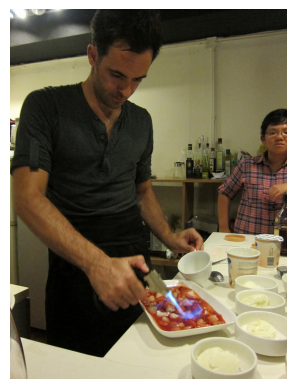

In [2]:
transform_test = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
])

data_loader = get_loader(transform=transform_test, mode="test",
                         vocab_file=str(config.VOCAB_FILE),
                         cocoapi_loc=str(config.COCO_ROOT))
vocab = data_loader.dataset.vocab

orig_image, image = next(iter(data_loader))
plt.imshow(np.squeeze(orig_image))
plt.axis("off")
plt.show()

## Load the trained model

`load_trained` passes `map_location` to `torch.load`, so the checkpoints (saved on a CUDA GPU) also load on Apple Silicon (MPS) or on the CPU.

In [3]:
encoder, decoder = load_trained(config.ENCODER_WEIGHTS, config.DECODER_WEIGHTS,
                                vocab_size=len(vocab),
                                embed_size=config.EMBED_SIZE,
                                hidden_size=config.HIDDEN_SIZE,
                                device=config.DEVICE)
print("Running on", config.DEVICE)

Running on mps


## Greedy decoding

`DecoderRNN.sample` feeds the image embedding in as the first input, then repeatedly takes the most likely token and feeds it back in as the next input. It always returns 20 token ids. `clean_sentence` cuts the list at `<end>` and turns it into text.

In [4]:
with torch.no_grad():
    features = encoder(image.to(config.DEVICE)).unsqueeze(1)
    output = decoder.sample(features)
print("token ids:", output)

token ids: [0, 3, 80, 13, 51, 224, 192, 3, 112, 21, 3, 577, 6, 3, 1449, 18, 1, 1, 1, 1]


In [5]:
def clean_sentence(output):
    """Convert a list of token ids into a caption string, stopping at <end>."""
    sentence = ""
    for i in output:
        word = vocab.idx2word[i]
        if word == vocab.start_word:
            continue
        if word == vocab.end_word:
            break
        sentence += word if word == "." else " " + word
    return sentence.strip()


print(clean_sentence(output))

a group of people sitting around a table with a cake and a knife.


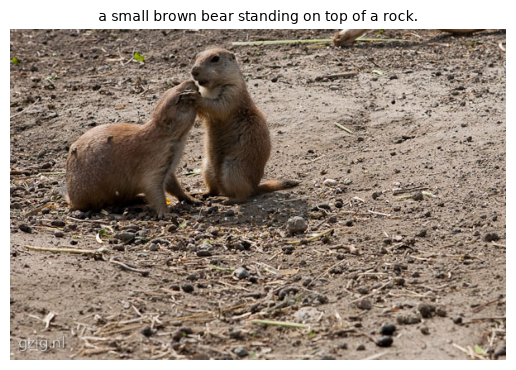

In [6]:
def get_prediction():
    """Caption a random test image and display it."""
    orig_image, image = next(iter(data_loader))
    with torch.no_grad():
        features = encoder(image.to(config.DEVICE)).unsqueeze(1)
        sentence = clean_sentence(decoder.sample(features))
    plt.imshow(np.squeeze(orig_image))
    plt.title(sentence, fontsize=10)
    plt.axis("off")
    plt.show()


get_prediction()

## Qualitative results

The examples below come from the run that was reviewed. They are saved in `assets/` because `get_prediction()` draws a new random image every time.

### Where it works

| | |
|---|---|
| ![](../assets/example_good_1.png) | ![](../assets/example_good_2.png) |
| *"a man in a hat and a brown horse"* | *"a large elephant standing in a field next to a tree."* |

- **Carriage.** Two men sit on a carriage pulled by two brown horses. The model picks out the main subjects and two details correctly: the top hat and the horses' color. Two things are missing. The caption has no verb, which is a common pattern with greedy decoding (it produces a noun phrase and then emits `<end>`). And it says *a* man and *a* horse, when there are two of each: a single pooled feature vector carries little information about how many objects there are.
- **Elephant.** The subject is correct, and the description of the setting is plausible. A more precise caption would say the elephant is *walking* along a dirt road between bushes. "Standing in a field next to a tree" is the most common way to phrase this in COCO, and the model falls back to it.

### Where it fails

| | | |
|---|---|---|
| ![](../assets/example_bad_1.png) | ![](../assets/example_bad_2.png) | ![](../assets/example_bad_3.png) |
| *"a baseball player is swinging at a ball."* | *"a cat is sitting on a chair with a cat."* | *"a man standing next to a computer on a desk."* |

1. **Wrong action, from the dataset prior.** The player is a fielder wearing a glove, in the middle of a throw. No bat is visible. In COCO, baseball captions are dominated by "swinging at a ball", and a frozen, globally pooled ResNet feature doesn't capture body pose in enough detail to override that prior. The model recognizes the *scene* correctly but reads the *action* from how often phrases appear in the training captions.
2. **Wrong furniture, and a repeated object.** There is one cat, lying with its head on a desk next to a keyboard. Two errors: "chair" instead of desk, and "with a cat" repeated at the end. Greedy decoding with no memory of which objects it already mentioned (no attention, no coverage) tends to bring back the highest-probability noun. The strong orange color cast is also far from typical training images.
3. **Out of distribution: a picture of a screen.** The image is a TV showing the scoreboard of a bowling video game, with two cartoon avatars. The model maps the faces to "man", the screen to "computer", and the dark room to "desk", which is a common COCO scene. It has no way to describe *what is shown on* a screen as different from the objects in the room.

## Limitations and next steps

- **Greedy decoding:** beam search (k = 3–5) usually produces more grammatical captions and fewer repetitions.
- **No quantitative evaluation:** report BLEU-4, METEOR and CIDEr on a held-out split of COCO val2014.
- **A single global image vector:** soft attention over the spatial ResNet feature map ([Show, Attend and Tell](https://arxiv.org/abs/1502.03044)) would help with counting, pose and small objects.
- **Frozen backbone:** fine-tuning the last ResNet block, or switching to a stronger encoder, after the decoder has converged.